In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

DATA_PATH = Path("../data/processed/email_cleaned.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (108684, 21)


,sender,sender_domain,receiver,receiver_domain,date,subject,content_types,body,urls,url_count,...,url_length_avg,url_subdom_max,url_subdom_avg,attachment_count,has_attachments,attachment_types,language,source,label,has_url
0,d66e9e64b006d6bca649f1c945129c42c43836872b2ead...,enron.com,35c5a9fb9fba3b8737ed7cef2a87e427a73db4fca85f6b...,enron.com,2001-06-29 09:37:04-05:00,[ORGANIZATION] failover plan.,text/plain,"Hi [NAME], \n\nTonight we are rolling out a n...",[NO URL],0.0,...,0.0,0.0,0.0,0.0,False,none,en,trec5,0.0,False
1,0907d5c64598aa2639154ed4e1556be615669e40052a1f...,enron.com,aa2c35499eae5999bf6080453cc719a891da2bb0c3803d...,enron.com,2001-06-29 08:39:30-05:00,RE: Intranet Site,text/plain,"[NAME] r these new?\tIntranet Site\n\n[NAME],\...",http://eastpower.dev.corp.enron.com/summary/pj...,3.0,...,58.0,3.0,3.0,0.0,False,none,en,trec5,0.0,True
2,7c3201a5ff8c5985218f1e3f11e330dc0242bbd28c6c20...,enron.com,a736837579feb601fbf6c0657d3d93689774afa6491bb9...,enron.com;enron.com,2001-06-29 10:35:17-05:00,FW: [ORGANIZATION] Company information,text/plain,"[NAME]/[NAME],\n\nWe are currently trading und...",[NO URL],0.0,...,0.0,0.0,0.0,0.0,False,none,en,trec5,0.0,False
3,8531d54a169c4af106b9ea2165d4986b8cc10fc0a6bb9b...,enron.com,765a3ec4a67e40118d22de5729b05d090a1b59cb443bf6...,enron.com;enron.com,2001-06-29 10:40:02-05:00,New Master Physical,text/plain,[NAME] and [NAME] -\n\nAttached is a worksheet...,[NO URL],0.0,...,0.0,0.0,0.0,0.0,False,none,en,trec5,0.0,False
4,7c3201a5ff8c5985218f1e3f11e330dc0242bbd28c6c20...,enron.com,ce418c97ac415706338972e1dbbd99ebb8c617b5c937a3...,enron.com;enron.com;enron.com,2001-06-29 10:48:00-05:00,FW: [ORGANIZATION]/Mirant GISB,text/plain,FYI. Below is a copy of my communication with ...,[NO URL],0.0,...,0.0,0.0,0.0,0.0,False,none,en,trec5,0.0,False


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 108684 entries, 0 to 108683
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   sender            108684 non-null  str    
 1   sender_domain     108684 non-null  str    
 2   receiver          108684 non-null  str    
 3   receiver_domain   108684 non-null  str    
 4   date              108684 non-null  str    
 5   subject           108684 non-null  str    
 6   content_types     108684 non-null  str    
 7   body              108684 non-null  str    
 8   urls              108684 non-null  str    
 9   url_count         108684 non-null  float64
 10  url_length_max    108684 non-null  float64
 11  url_length_avg    108684 non-null  float64
 12  url_subdom_max    108684 non-null  float64
 13  url_subdom_avg    108684 non-null  float64
 14  attachment_count  108684 non-null  float64
 15  has_attachments   108684 non-null  bool   
 16  attachment_types  108684 non-nu

In [4]:
df.columns.tolist()

['sender',
 'sender_domain',
 'receiver',
 'receiver_domain',
 'date',
 'subject',
 'content_types',
 'body',
 'urls',
 'url_count',
 'url_length_max',
 'url_length_avg',
 'url_subdom_max',
 'url_subdom_avg',
 'attachment_count',
 'has_attachments',
 'attachment_types',
 'language',
 'source',
 'label',
 'has_url']

### 1. Subject Length

In [5]:
df['subject_length'] = df['subject'].str.len()

In [6]:
df[['subject', 'subject_length']].head(10)

,subject,subject_length
0,[ORGANIZATION] failover plan.,29
1,RE: Intranet Site,17
2,FW: [ORGANIZATION] Company information,38
3,New Master Physical,19
4,FW: [ORGANIZATION]/Mirant GISB,30
5,[ORGANIZATION] Receives Open Season Requests T...,66
6,Internet Advertising agreement,30
7,FW: Internet Advertising agreement,34
8,[ORGANIZATION] Oil Invoice,26
9,"Accepted: Internet Meeting - [NAME], [NAME], [...",59


In [7]:
df['subject_length'].describe()

count    108684.000000
mean         42.200692
std          47.372757
min           1.000000
25%          20.000000
50%          32.000000
75%          47.000000
max        3701.000000
Name: subject_length, dtype: float64

In [8]:
# Subject word count
df['subject_word_count'] = df['subject'].str.split().str.len()

# Body length
df['body_length'] = df['body'].str.len()

# Body word count
df['body_word_count'] = df['body'].str.split().str.len()

In [9]:
# Validate all four features
text_features = [
    'subject_length',
    'subject_word_count',
    'body_length',
    'body_word_count'
]

df[text_features].describe()

,subject_length,subject_word_count,body_length,body_word_count
count,108684.000000,108684.000000,108684.000000,108684.000000
mean,42.200692,5.311895,1168.111323,171.744893
std,47.372757,3.795233,1141.704225,164.932574
min,1.000000,1.000000,1.000000,1.000000
25%,20.000000,3.000000,380.000000,55.000000
50%,32.000000,5.000000,797.000000,121.000000
75%,47.000000,7.000000,1533.000000,227.000000
max,3701.000000,578.000000,30574.000000,1199.000000


### URL-Based Feature engineering

In [10]:
url_columns = [
    'urls',
    'url_count',
    'url_length_max',
    'url_length_avg',
    'url_subdom_max',
    'url_subdom_avg',
    'has_url'
]

df[url_columns].head(10)

,urls,url_count,url_length_max,url_length_avg,url_subdom_max,url_subdom_avg,has_url
0,[NO URL],0.0,0.0,0.0,0.0,0.0,False
1,http://eastpower.dev.corp.enron.com/summary/pj...,3.0,60.0,58.0,3.0,3.0,True
2,[NO URL],0.0,0.0,0.0,0.0,0.0,False
3,[NO URL],0.0,0.0,0.0,0.0,0.0,False
4,[NO URL],0.0,0.0,0.0,0.0,0.0,False
5,[NO URL],0.0,0.0,0.0,0.0,0.0,False
6,[NO URL],0.0,0.0,0.0,0.0,0.0,False
7,[NO URL],0.0,0.0,0.0,0.0,0.0,False
8,[NO URL],0.0,0.0,0.0,0.0,0.0,False
9,[NO URL],0.0,0.0,0.0,0.0,0.0,False


In [13]:
df['has_url_engineered'] = (df['url_count'] > 0)
print(df['has_url_engineered'].value_counts())

comparison = pd.crosstab(
    df['has_url'],
    df['has_url_engineered']
)

comparison

has_url_engineered
True     64052
False    44632
Name: count, dtype: int64


has_url_engineered,False,True
has_url,,
False,44632,0
True,0,64052


has_url_engineered,False,True
has_url,,
False,44632,0
True,0,64052


### URL-Length Transformation

In [18]:
df['url_length_max_log'] = np.log1p(df['url_length_max'])

df['url_length_avg_log'] = np.log1p(df['url_length_avg'])

df[
    [
        'url_length_max',
        'url_length_max_log',
        'url_length_avg',
        'url_length_avg_log'
    ]
].describe()

,url_length_max,url_length_max_log,url_length_avg,url_length_avg_log
count,108684.000000,108684.000000,108684.000000,108684.000000
mean,31.371379,2.262389,26.691573,2.191616
std,205.157299,1.927600,203.960722,1.858100
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000
50%,26.000000,3.295837,24.500000,3.238678
75%,48.000000,3.891820,43.500000,3.795489
max,66647.000000,11.107180,66647.000000,11.107180


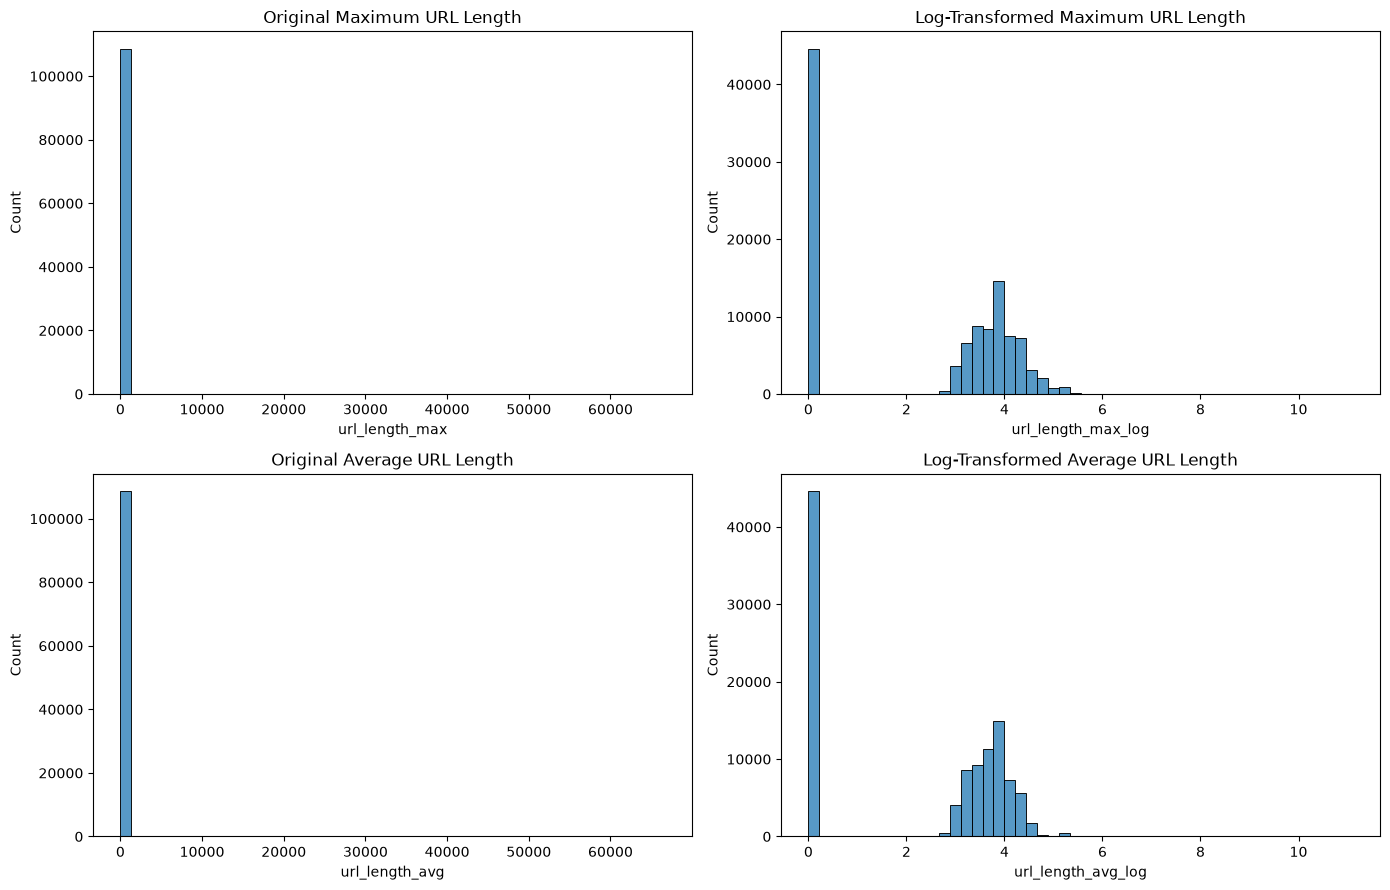

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(df['url_length_max'], bins=50, ax=axes[0, 0])
axes[0, 0].set_title('Original Maximum URL Length')

sns.histplot(df['url_length_max_log'], bins=50, ax=axes[0, 1])
axes[0, 1].set_title('Log-Transformed Maximum URL Length')

sns.histplot(df['url_length_avg'], bins=50, ax=axes[1, 0])
axes[1, 0].set_title('Original Average URL Length')

sns.histplot(df['url_length_avg_log'], bins=50, ax=axes[1, 1])
axes[1, 1].set_title('Log-Transformed Average URL Length')

plt.tight_layout()
plt.show()

### URL Sub-Domain Features

In [20]:
df[['url_subdom_max', 'url_subdom_avg']].describe()

,url_subdom_max,url_subdom_avg
count,108684.000000,108684.000000
mean,0.659545,0.585500
std,0.791753,0.712160
min,0.000000,0.000000
25%,0.000000,0.000000
50%,1.000000,0.215278
75%,1.000000,1.000000
max,5.000000,5.000000


In [21]:
df['url_subdom_max_log'] = np.log1p(df['url_subdom_max'])

df['url_subdom_avg_log'] = np.log1p(df['url_subdom_avg'])

In [22]:
df[
    [
        'url_subdom_max',
        'url_subdom_max_log',
        'url_subdom_avg',
        'url_subdom_avg_log'
    ]
].describe()

,url_subdom_max,url_subdom_max_log,url_subdom_avg,url_subdom_avg_log
count,108684.000000,108684.000000,108684.000000,108684.000000
mean,0.659545,0.407942,0.585500,0.375401
std,0.791753,0.433216,0.712160,0.402377
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.693147,0.215278,0.194956
75%,1.000000,0.693147,1.000000,0.693147
max,5.000000,1.791759,5.000000,1.791759


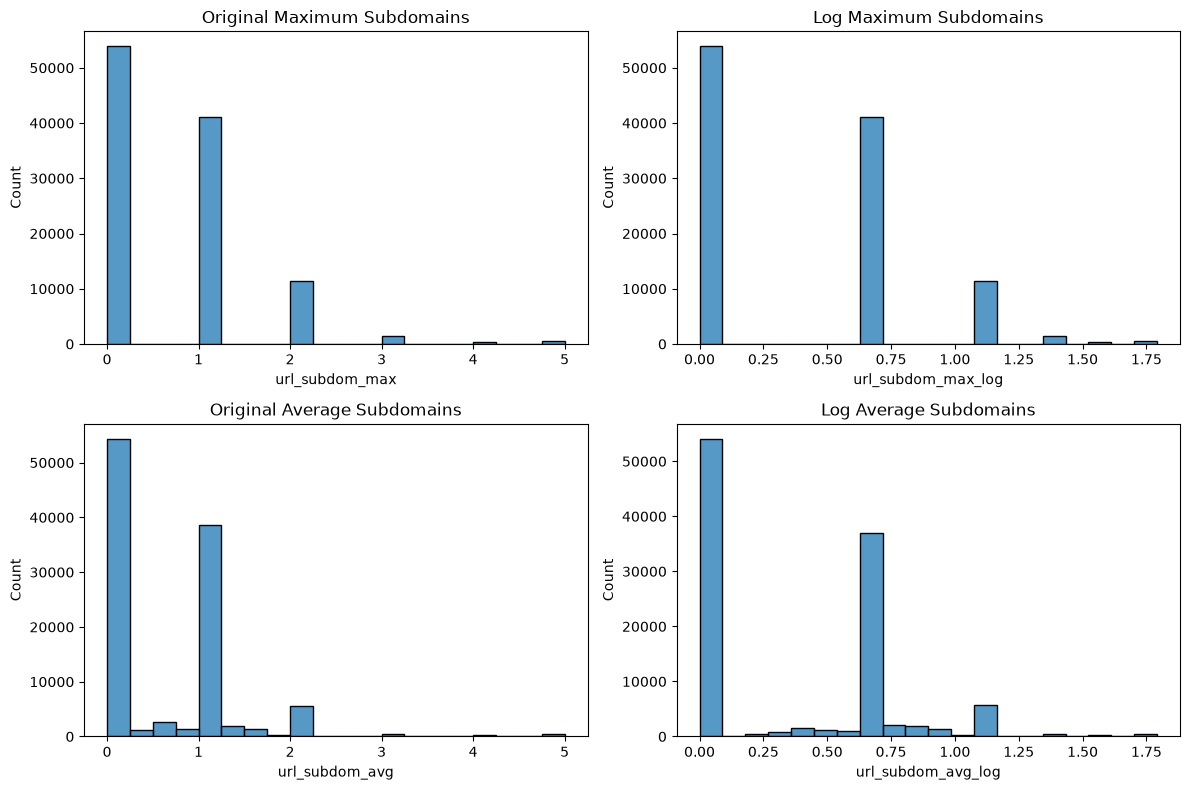

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df['url_subdom_max'], bins=20, ax=axes[0, 0])
axes[0, 0].set_title('Original Maximum Subdomains')

sns.histplot(df['url_subdom_max_log'], bins=20, ax=axes[0, 1])
axes[0, 1].set_title('Log Maximum Subdomains')

sns.histplot(df['url_subdom_avg'], bins=20, ax=axes[1, 0])
axes[1, 0].set_title('Original Average Subdomains')

sns.histplot(df['url_subdom_avg_log'], bins=20, ax=axes[1, 1])
axes[1, 1].set_title('Log Average Subdomains')

plt.tight_layout()
plt.show()

### Attachment Count Transformation

In [24]:
df['attachment_count'].describe()

count    108684.000000
mean          0.020785
std           0.274446
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          61.000000
Name: attachment_count, dtype: float64

In [25]:
df['attachment_count'].value_counts().sort_index().head(20)

attachment_count
0.0     107018
1.0       1375
2.0        186
3.0         43
4.0         30
5.0         16
6.0          7
7.0          1
8.0          4
12.0         1
13.0         1
16.0         1
61.0         1
Name: count, dtype: int64

In [26]:
df['attachment_count_log'] = np.log1p(df['attachment_count'])

In [27]:
# Create an attachment presence indicator
df['has_attachments_engineered'] = (
    df['attachment_count'] > 0
)

In [30]:
# Validate the new feature

print(df['has_attachments_engineered'].value_counts())

df[
    [
        'attachment_count',
        'attachment_count_log',
        'has_attachments_engineered'
    ]
].head(15)


has_attachments_engineered
False    107018
True       1666
Name: count, dtype: int64


,attachment_count,attachment_count_log,has_attachments_engineered
0,0.0,0.0,False
1,0.0,0.0,False
2,0.0,0.0,False
3,0.0,0.0,False
4,0.0,0.0,False
5,0.0,0.0,False
6,0.0,0.0,False
7,0.0,0.0,False
8,0.0,0.0,False
9,0.0,0.0,False


## Categorical Feature Engineering

In [37]:
print (df[['sender', 'sender_domain']].head(10))

print('\n',df['sender_domain'].nunique())

print('\n',df['sender_domain'].value_counts().head(15))

                                              sender sender_domain
0  d66e9e64b006d6bca649f1c945129c42c43836872b2ead...     enron.com
1  0907d5c64598aa2639154ed4e1556be615669e40052a1f...     enron.com
2  7c3201a5ff8c5985218f1e3f11e330dc0242bbd28c6c20...     enron.com
3  8531d54a169c4af106b9ea2165d4986b8cc10fc0a6bb9b...     enron.com
4  7c3201a5ff8c5985218f1e3f11e330dc0242bbd28c6c20...     enron.com
5  d8b1e48bf530bae64465908ad98f9757cb9ae89f409ca4...     enron.com
6  ffe499b8558e2216fb91179d6bbaec518c79599386cfc6...     enron.com
7  ffe499b8558e2216fb91179d6bbaec518c79599386cfc6...     enron.com
8  17f0b47f7f6cc8a26d10f7afbffa247fc9a730d44b25c3...     enron.com
9  0ac8edf9f46533ba774c9834c14614fc04663645614b76...     enron.com

 28465

 sender_domain
enron.com                    21684
gmail.com                     2909
samba.org                     2604
yahoo.com                     2169
hotmail.com                   1542
psy1.psych.arizona.edu        1102
aol.com                      

In [38]:
print("Missing values:")
print(df['sender_domain'].isna().sum())

print("\nUnknown values:")
print(
    df['sender_domain']
    .astype(str)
    .str.lower()
    .eq('unknown')
    .sum()
)

Missing values:
0

Unknown values:
494


In [39]:
domain_counts = df['sender_domain'].value_counts()

print("Domains appearing once:",
      (domain_counts == 1).sum())

print("Domains appearing fewer than 5 times:",
      (domain_counts < 5).sum())

print("Domains appearing fewer than 10 times:",
      (domain_counts < 10).sum())

Domains appearing once: 21348
Domains appearing fewer than 5 times: 26213
Domains appearing fewer than 10 times: 27474


In [41]:
rare_domains = (domain_counts == 1).sum()

percentage = (rare_domains / df['sender_domain'].nunique()) * 100

print(f"Singleton domains: {percentage:.2f}%")

Singleton domains: 75.00%


In [42]:
df['sender_domain'].value_counts().head(20)

sender_domain
enron.com                    21684
gmail.com                     2909
samba.org                     2604
yahoo.com                     2169
hotmail.com                   1542
psy1.psych.arizona.edu        1102
aol.com                        817
mail.cnn.com                   716
broadcast.shareholder.com      689
yahoo.co.kr                    565
unknown                        494
msn.com                        486
enron.net                      448
media.mit.edu                  375
earthlink.net                  337
messaging.accuweather.com      333
parrotcode.org                 328
cbsig.com                      291
caiso.com                      246
stats.ox.ac.uk                 239
Name: count, dtype: int64

In [43]:
# Percentage of unique domains appearing once.
# Percentage of email records belonging to those singleton domains.

# Map each domain to its frequency
sender_domain_frequency = df['sender_domain'].map(domain_counts)

# Count email records belonging to singleton domains
singleton_email_count = (sender_domain_frequency == 1).sum()

# Calculate percentage
singleton_email_percentage = (
    singleton_email_count / len(df)
) * 100

print("Emails belonging to singleton domains:",
      singleton_email_count)

print("Percentage of total emails:",
      round(singleton_email_percentage, 2), "%")

Emails belonging to singleton domains: 21348
Percentage of total emails: 19.64 %


### Conclusion

The sender domain feature contains 28,465 unique categories, with approximately 75% of them appearing only once. This indicates high cardinality.

Applying One-Hot Encoding directly would create a large number of additional features.

Therefore, we decided to:

* Retain the original `sender_domain` and `receiver_domain` columns.
* Avoid applying One-Hot Encoding directly.
* Consider grouping infrequent categories before encoding.
* Explore Frequency Encoding as an alternative.
* Perform encoding during model preprocessing rather than feature engineering.

The final encoding strategy will be selected based on model performance and generalization.


## Receiver Domain Analysis

In [44]:
df[['receiver', 'receiver_domain']].head(10)

,receiver,receiver_domain
0,35c5a9fb9fba3b8737ed7cef2a87e427a73db4fca85f6b...,enron.com
1,aa2c35499eae5999bf6080453cc719a891da2bb0c3803d...,enron.com
2,a736837579feb601fbf6c0657d3d93689774afa6491bb9...,enron.com;enron.com
3,765a3ec4a67e40118d22de5729b05d090a1b59cb443bf6...,enron.com;enron.com
4,ce418c97ac415706338972e1dbbd99ebb8c617b5c937a3...,enron.com;enron.com;enron.com
5,7e8ef4e21d2269152a6f2271f2caec52926af1341b695c...,enron.com;enron.com;enron.com;enron.com;enron....
6,3342c136f6950df416ba6bcbe0bb281925640e82674641...,enron.com
7,3342c136f6950df416ba6bcbe0bb281925640e82674641...,enron.com
8,f861c3ced6ee772dde79131f9a6e544a250f657c000ef0...,enron.com;enron.com
9,1aef9ef79ea552c8908beaf58a9422f7f6c18995363b80...,enron.com


In [45]:
print("Unique receiver domains:",
      df['receiver_domain'].nunique())

print("\nTop 20 receiver domains:")

receiver_domain_counts = df['receiver_domain'].value_counts()

display(receiver_domain_counts.head(20))

Unique receiver domains: 6367

Top 20 receiver domains:


receiver_domain
enron.com                                                      30845
flax9.uwaterloo.ca                                              9868
plg.uwaterloo.ca                                                6931
speedy.uwaterloo.ca                                             6065
media.mit.edu                                                   4675
enron.com;enron.com                                             2988
psy1.psych.arizona.edu                                          2664
stat.math.ethz.ch                                               2468
unknown                                                         2371
samba.org                                                       2368
perl.org                                                        1738
plg2.math.uwaterloo.ca                                          1525
ect.enron.com                                                   1475
flax24.uwaterloo.ca                                             1235
braille.uwo.ca    

In [46]:
print("Domains appearing once:",
      (receiver_domain_counts == 1).sum())

print("Domains appearing fewer than 5 times:",
      (receiver_domain_counts < 5).sum())

print("Domains appearing fewer than 10 times:",
      (receiver_domain_counts < 10).sum())

Domains appearing once: 4331
Domains appearing fewer than 5 times: 5661
Domains appearing fewer than 10 times: 6015


In [48]:
# Count recipient-domain entries
df['receiver_domain_count'] = (
    df['receiver_domain']
    .fillna('')
    .str.split(';')
    .apply(lambda x: len([d for d in x if d.strip()]))
)

df['receiver_domain_count'].describe()

count    108684.000000
mean          2.432400
std           8.424601
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max         526.000000
Name: receiver_domain_count, dtype: float64

In [49]:
df['receiver_domain_count'].value_counts().sort_index().head(20)

receiver_domain_count
1     92489
2      6087
3      1684
4      1156
5       909
6       878
7       608
8       498
9       405
10      339
11      250
12      239
13      189
14      147
15      183
16      115
17      132
18       82
19      120
20      109
Name: count, dtype: int64

In [51]:
# Create receiver_unique_domain_count
df['receiver_unique_domain_count'] = (
    df['receiver_domain']
    .fillna('')
    .apply(
        lambda x: len(set(
            domain.strip().lower()
            for domain in x.split(';')
            if domain.strip()
        ))
    )
)

df[
    [
        'receiver_domain',
        'receiver_domain_count',
        'receiver_unique_domain_count'
    ]
].head(20)

,receiver_domain,receiver_domain_count,receiver_unique_domain_count
0,enron.com,1,1
1,enron.com,1,1
2,enron.com;enron.com,2,1
3,enron.com;enron.com,2,1
4,enron.com;enron.com;enron.com,3,1
5,enron.com;enron.com;enron.com;enron.com;enron....,67,1
6,enron.com,1,1
7,enron.com,1,1
8,enron.com;enron.com,2,1
9,enron.com,1,1


In [52]:
df[
    [
        'receiver_domain_count',
        'receiver_unique_domain_count'
    ]
].describe()

,receiver_domain_count,receiver_unique_domain_count
count,108684.000000,108684.000000
mean,2.432400,1.175647
std,8.424601,2.170889
min,1.000000,1.000000
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,1.000000,1.000000
max,526.000000,391.000000


In [59]:
# Now let's create a Boolean feature that identifies whether an email has more than one distinct receiver domain.
df['has_multiple_receiver_domains'] = (
    df['receiver_unique_domain_count'] > 1
)

print(df['has_multiple_receiver_domains'].value_counts())

print('\n',df['has_multiple_receiver_domains'].value_counts(
    normalize=True
).mul(100).round(2))

has_multiple_receiver_domains
False    102626
True       6058
Name: count, dtype: int64

 has_multiple_receiver_domains
False    94.43
True      5.57
Name: proportion, dtype: float64


### Conclusion

The `receiver_domain` column contains 6,367 unique domain combinations. Multiple occurrences of the same domain are present within individual records.

To capture this information, three features were created:

* `receiver_domain_count`: Total number of receiver-domain entries.
* `receiver_unique_domain_count`: Number of distinct receiver domains.
* `has_multiple_receiver_domains`: Indicates whether an email contains multiple distinct receiver domains.

The analysis showed that 94.43% of emails have a single distinct receiver domain, while 5.57% contain multiple distinct domains.

The original `receiver_domain` column will be retained. Encoding strategies will be evaluated during model preprocessing.


### Email Meta Feature Engineering

##### 1. Content Types

In [60]:
print("Unique content types:",
      df['content_types'].nunique())

print("\nContent type distribution:")

df['content_types'].value_counts().head(20)

Unique content types: 17

Content type distribution:


content_types
text/plain                                                                                                                             70992
text/plain;text/html                                                                                                                   21173
text/html                                                                                                                              15270
text/plain;text/plain                                                                                                                    989
text/plain;text/html;text/plain                                                                                                          149
text/html;text/plain                                                                                                                      40
text/plain;text/plain;text/plain                                                                                                          34

In [65]:
# We can create a Boolean feature indicating whether an email contains HTML content.
df['has_html_content'] = (
    df['content_types']
    .fillna('')
    .str.contains('text/html', case=False)
)

print(df['has_html_content'].value_counts())
print('\n',df['has_html_content'].value_counts(
    normalize=True
).mul(100).round(2))

has_html_content
False    72026
True     36658
Name: count, dtype: int64

 has_html_content
False    66.27
True     33.73
Name: proportion, dtype: float64


In [68]:
# Create has_plain_text
df['has_plain_text'] = (
    df['content_types']
    .fillna('')
    .str.contains('text/plain', case=False)
)
print(df['has_plain_text'].value_counts())
print('\n',df['has_plain_text'].value_counts(normalize=True).mul(100).round(2))

has_plain_text
True     93410
False    15274
Name: count, dtype: int64

 has_plain_text
True     85.95
False    14.05
Name: proportion, dtype: float64


In [70]:
# Create has mixed content
df['has_mixed_content'] = (
    df['has_html_content'] & df['has_plain_text']
)
print(df['has_mixed_content'].value_counts())
print('\n',df['has_mixed_content'].value_counts(normalize=True).mul(100).round(2))

has_mixed_content
False    87299
True     21385
Name: count, dtype: int64

 has_mixed_content
False    80.32
True     19.68
Name: proportion, dtype: float64


### Content Type Feature Engineering

Created three Boolean features from the `content_types` column:

* `has_html_content`: Indicates whether the email contains HTML content.
* `has_plain_text`: Indicates whether the email contains plain-text content.
* `has_mixed_content`: Indicates whether the email contains both HTML and plain-text content.

The distribution shows that 85.95% of emails contain plain text, 33.73% contain HTML, and 19.68% contain both formats.

These features capture email formatting characteristics that may help distinguish between benign and phishing emails. The original `content_types` column is retained for further analysis and preprocessing.


#### Timestamp Features

In [76]:
print(df['date'].dtype)

print('\n',df['date'].head(10))

str

 0    2001-06-29 09:37:04-05:00
1    2001-06-29 08:39:30-05:00
2    2001-06-29 10:35:17-05:00
3    2001-06-29 10:40:02-05:00
4    2001-06-29 10:48:00-05:00
5    2001-06-29 11:03:51-05:00
6    2001-06-29 13:36:42-05:00
7    2001-06-29 14:17:38-05:00
8    2001-06-29 14:39:54-05:00
9    2001-06-29 15:16:54-05:00
Name: date, dtype: str


In [77]:
# Convert the 'date' column to datetime format
df['date'] = pd.to_datetime(
    df['date'],
    errors='coerce',
    utc=True
)

In [78]:
print("Data type:", df['date'].dtype)

print("\nMissing timestamps:", df['date'].isna().sum())

print("\nTimestamp range:")
print("Minimum:", df['date'].min())
print("Maximum:", df['date'].max())

Data type: datetime64[us, UTC]

Missing timestamps: 0

Timestamp range:
Minimum: 1889-05-19 08:59:51+00:00
Maximum: 2102-03-16 15:16:56+00:00


In [79]:
# Count emails by year
df['date_year'] = df['date'].dt.year

df['date_year'].describe()


count    108684.000000
mean       2003.188657
std           6.482579
min        1889.000000
25%        2001.000000
50%        2002.000000
75%        2007.000000
max        2102.000000
Name: date_year, dtype: float64

In [80]:
# Step 2: Count suspicious timestamps

suspicious_dates = df[
    (df['date'].dt.year < 1990) |
    (df['date'].dt.year > 2026)
]

print("Suspicious records:", len(suspicious_dates))
print("\nPercentage:", round(
    len(suspicious_dates) / len(df) * 100, 2
), "%")

Suspicious records: 432

Percentage: 0.4 %


In [81]:
suspicious_dates[['date', 'label']].head(20)

,date,label
113,1898-06-16 08:10:42+00:00,1.0
114,1898-06-16 14:13:26+00:00,1.0
125,1898-06-16 08:01:06+00:00,1.0
280,1898-06-17 07:23:06+00:00,1.0
281,1898-06-16 23:23:39+00:00,1.0
1014,1898-06-21 05:12:49+00:00,1.0
1199,1898-06-22 07:46:26+00:00,1.0
1845,1898-06-24 23:35:50+00:00,1.0
2248,1898-06-26 17:04:19+00:00,1.0
2373,1898-06-27 08:24:18+00:00,1.0


In [82]:
suspicious_dates['date'].dt.year.value_counts().sort_index()

date
1889      2
1890      1
1893      4
1894     16
1895      5
1896      5
1897      1
1898    163
1899      1
1900      4
1901     10
1902      1
1903      1
1904      3
1906      1
1910      1
1912      1
1913      4
1918     30
1919      1
1928     21
1929      4
1930      2
1931      2
1932     12
1933      3
1934     95
1936      1
1937      1
1956      1
1970      3
1980      6
1983      1
1987      5
2027      2
2034      1
2036      1
2038      6
2080      1
2087      2
2090      4
2099      1
2102      2
Name: count, dtype: int64

In [83]:
pd.crosstab(
    suspicious_dates['date'].dt.year,
    suspicious_dates['label']
)

label,0.0,1.0
date,,
1889,0,2
1890,0,1
1893,0,4
1894,0,16
1895,0,5
1896,0,5
1897,0,1
1898,0,163
1899,0,1


In [85]:
df_original.loc[
    pd.to_datetime(
        df_original['date'],
        errors='coerce',
        utc=True
    ).dt.year == 1898,
    ['date', 'label', 'sender', 'subject']
].head(10)

,date,label,sender,subject
113,1898-06-16 09:10:42+01:00,1.0,c37e3eea966c89607f9f001a9078f03fc197e2c9a4619f...,<|SIMBOL|>X<|SIMBOL|>Y<|SIMBOL|>M<|SIMBOL|>Õ<|...
114,1898-06-16 09:13:26-05:00,1.0,b260193d679d8776d5a339d78014754762ea8365ee3e76...,<|SIMBOL|>C<|SIMBOL|>í<|SIMBOL|>n<|SIMBOL|>`<|...
125,1898-06-16 10:01:06+02:00,1.0,afceed624b47bbd46c14693f7d5ebea6952b7ef052db2a...,<|SIMBOL|>Õ<|SIMBOL|>Õ<|SIMBOL|><|SIMBOL|><|SI...
280,1898-06-17 04:23:06-03:00,1.0,abe69d6eceec693d8e6cd440dcd223aef9c0e61ded6719...,<|SIMBOL|>o<|SIMBOL|>Ë<|SIMBOL|><|SIMBOL|><|SI...
281,1898-06-17 04:23:39+05:00,1.0,7469bacf3ecb154f502febc662e2e571b1cf2388eb3017...,<|SIMBOL|>Õ<|SIMBOL|>Õ<|SIMBOL|><|SIMBOL|><|SI...
1014,1898-06-21 08:12:49+03:00,1.0,ee8970e7ada5c63e07c107144add70c1dc3bdd9828b801...,<|SIMBOL|>Q<|SIMBOL|>Ç<|SIMBOL|>é<|SIMBOL|>y<|...
1199,1898-06-22 01:46:26-06:00,1.0,aaa7f373491a2df8a15116d5171f7c5a05018b99cd2e1b...,<|SIMBOL|><|SIMBOL|><|SIMBOL|>ÕÂI<|SIMBOL|>Ó<|...
1845,1898-06-25 00:35:50+01:00,1.0,f8d3ce3fbb36e26b221984cde2f5d67302ef399917c786...,<|SIMBOL|>b<|SIMBOL|>W<|SIMBOL|>ü<|SIMBOL|>óÀY...
2248,1898-06-26 12:04:19-05:00,1.0,02645cee4bd8866d9950dfe9ccb2710a2e587d52fcd101...,<|SIMBOL|>Q<|SIMBOL|>ü<|SIMBOL|>H<|SIMBOL|>Û<|...
2373,1898-06-27 07:24:18-01:00,1.0,af3235825b3b11c2465ab291ce989b4ba5b0138237530f...,<|SIMBOL|>i<|SIMBOL|>Ð<|SIMBOL|>Ç<|SIMBOL|>jÂ<...


In [86]:
records_1898 = df_original[
    pd.to_datetime(
        df_original['date'],
        errors='coerce',
        utc=True
    ).dt.year == 1898
]

print("Total records:", len(records_1898))

print("\nUnique senders:")
print(records_1898['sender'].nunique())

print("\nTop senders:")
print(records_1898['sender'].value_counts().head(10))

Total records: 163

Unique senders:
160

Top senders:
sender
c37e3eea966c89607f9f001a9078f03fc197e2c9a4619fc012b1147a8dfd0610    1
b260193d679d8776d5a339d78014754762ea8365ee3e76e43f87054e1e8b4ee3    1
afceed624b47bbd46c14693f7d5ebea6952b7ef052db2a0a44c5169abfb9dedc    1
abe69d6eceec693d8e6cd440dcd223aef9c0e61ded6719442edf64016708babf    1
7469bacf3ecb154f502febc662e2e571b1cf2388eb3017173077fdfc054125ee    1
ee8970e7ada5c63e07c107144add70c1dc3bdd9828b8012a057105fac9401503    1
aaa7f373491a2df8a15116d5171f7c5a05018b99cd2e1bd295cca27242609aa3    1
f8d3ce3fbb36e26b221984cde2f5d67302ef399917c786fe61ee2ae70ff93ac0    1
02645cee4bd8866d9950dfe9ccb2710a2e587d52fcd10107d617327602188f90    1
af3235825b3b11c2465ab291ce989b4ba5b0138237530fb1949bb8ce6e36b035    1
Name: count, dtype: int64


In [88]:
# Handle invalid timestamps
invalid_date_mask = (
    (df['date'].dt.year < 1990) |
    (df['date'].dt.year > 2026)
)

df.loc[invalid_date_mask, 'date'] = pd.NaT

In [89]:
print("Invalid timestamps remaining:", 
      ((df['date'].dt.year < 1990) |
       (df['date'].dt.year > 2026)).sum())

print("Missing timestamps:", df['date'].isna().sum())

Invalid timestamps remaining: 0
Missing timestamps: 432


In [91]:
# So, create a new feature for year
df['date_year'] = df['date'].dt.year
print(df['date_year'].value_counts().sort_index())

date_year
1990.0       34
1992.0        1
1993.0      164
1994.0      269
1995.0      127
1996.0       20
1997.0       15
1998.0     3395
1999.0     3620
2000.0     2124
2001.0    32710
2002.0    17619
2003.0      814
2004.0      886
2005.0     1550
2006.0     1448
2007.0    43421
2008.0       15
2009.0        5
2010.0        1
2012.0        1
2015.0        3
2017.0        2
2019.0        1
2020.0        3
2022.0        2
2023.0        1
2025.0        1
Name: count, dtype: int64


In [92]:
print("Missing years:", df['date_year'].isna().sum())
print("Unique years:", df['date_year'].nunique())

Missing years: 432
Unique years: 28


### Timestamp Feature Engineering

Converted the original `date` column from string format into a timezone-aware datetime format.

During investigation, 432 records (0.40% of the dataset) were found to contain suspicious timestamps outside the provisional 1990–2026 range. These timestamps were replaced with `NaT`, while preserving all email records.

Created one temporal feature:

* `date_year`: Extracts the year from the email timestamp.

The resulting feature contains 28 unique valid years and 432 missing values. Month, day, hour, and weekday features were excluded because they were not considered necessary for the current project.

The original `date` column was retained.


### Language feature

In [94]:
print("Unique languages:", df['language'].nunique())

print("\nMissing values:", df['language'].isna().sum())

print("\nLanguage distribution:")
print(df['language'].value_counts().head(20))

Unique languages: 243

Missing values: 0

Language distribution:
language
en          82175
en;en       21250
ru            827
ja            602
de            383
es            332
zh            315
fr            303
tr;en         284
en;en;en      218
pl            114
de;en         101
uk             91
pt             85
de;de          77
sl             70
fi             60
pt;pt          58
nl             57
it             50
Name: count, dtype: int64


In [95]:
# Understand the language structure
print("Total unique language combinations:",
      df['language'].nunique())

print("\nMissing values:",
      df['language'].isna().sum())

print("\nLanguage value counts:")
print(df['language'].value_counts().tail(20))

Total unique language combinations: 243

Missing values: 0

Language value counts:
language
la             1
mk             1
eu;en          1
sl;en          1
ar;en          1
da;en          1
vi;en          1
en;es;es;nl    1
pl;en;en       1
eu;de          1
te;en          1
en;lv          1
sw;en          1
de;en;en       1
fi;sl          1
de;fi          1
kw;de          1
wuu;wuu        1
sv;nl          1
lt;zh          1
Name: count, dtype: int64


In [96]:
df['language_count'] = (
    df['language']
    .fillna('')
    .str.split(';')
    .apply(lambda x: len([lang for lang in x if lang.strip()]))
)

df['language_count'].value_counts().sort_index()

language_count
1     85936
2     22390
3       229
4        43
5        14
6        27
7        12
8         9
9        11
10        3
11        1
12        3
14        1
18        1
19        1
22        1
24        1
25        1
Name: count, dtype: int64

In [97]:
OUTPUT_PATH = Path("../data/processed/email_feature_engineered.csv")

df.to_csv(OUTPUT_PATH, index=False)

print(f"Dataset saved successfully: {OUTPUT_PATH}")

Dataset saved successfully: ..\data\processed\email_feature_engineered.csv
